<a href="https://colab.research.google.com/github/yashinrush/dbms/blob/main/ML_2ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [ ]:
df = pd.read_csv("emails.csv")

In [ ]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
df.isnull().sum()

,0
Email No.,0
the,0
to,0
ect,0
and,0
...,...
military,1
allowing,1
ff,1
dry,1


In [ ]:
X = df.iloc[:,1:3001]

,the,to,ect,and,for,of,a,you,hou,in,...,enhancements,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry
0,0,0,1,0,0,0,2,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,8,13,24,6,6,2,102,1,27,18,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0,0,1,0,0,0,8,0,0,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,5,22,0,5,1,51,2,10,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,7,6,17,1,5,2,57,0,9,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2076,15,12,18,4,13,0,93,5,10,12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2077,3,3,1,4,6,2,42,3,0,11,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2078,13,17,27,5,6,5,114,3,12,18,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
2079,2,1,1,1,2,2,11,0,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
Y = df.iloc[:,-1].values
Y

array([ 0.,  0.,  0., ...,  0.,  0., nan])

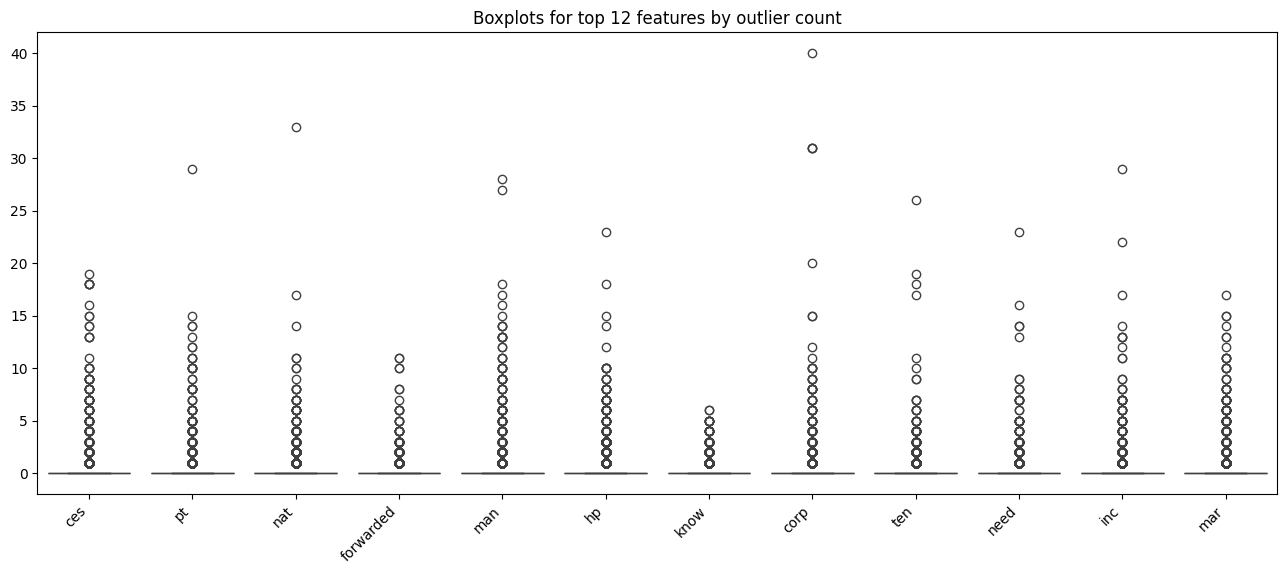

In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Visualize outliers
import matplotlib.pyplot as plt
import seaborn as sns
df_numeric = df[numeric_cols]
Q1 = df_numeric.quantile(0.25)
Q3 = df_numeric.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outlier_mask = ((df_numeric < lower) | (df_numeric > upper))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

# pick top N features
topN = 12
top_features = outlier_counts.head(topN).index.tolist()

plt.figure(figsize=(16,6))
sns.boxplot(data=df_numeric[top_features])
plt.title(f"Boxplots for top {topN} features by outlier count")
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# -------- Support Vector Machine --------
svc = SVC(C=1.0, kernel='rbf', gamma='auto')
svc.fit(X_train  y_train)
svc_pred = svc.predict(X_test)

SVC Model Accuracy: 0.8846153846153846

Classification Report:
               precision    recall  f1-score   support

         0.0       0.87      0.99      0.93       379
         1.0       0.95      0.61      0.74       141

    accuracy                           0.88       520
   macro avg       0.91      0.80      0.83       520
weighted avg       0.89      0.88      0.88       520



In [ ]:
print("SVM Accuracy:", accuracy_score(y_test, svc_pred))
print("SVM Classification Report:\n", classification_report(y_test, svc_pred))
print("SVM Confusion Matrix:\n", confusion_matrix(y_test, svc_pred))

SVM Accuracy: 0.8846153846153846
SVM Classification Report:
               precision    recall  f1-score   support

         0.0       0.87      0.99      0.93       379
         1.0       0.95      0.61      0.74       141

    accuracy                           0.88       520
   macro avg       0.91      0.80      0.83       520
weighted avg       0.89      0.88      0.88       520

SVM Confusion Matrix:
 [[374   5]
 [ 55  86]]
